In [61]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

In [47]:
# Ingesting Dataset
df=pd.read_csv(r"data/course_lead_scoring_2026.csv")

In [48]:
# Architectural Inspection
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 526.0 KB


In [49]:
# Seperating Numerical and Categorical features
categorical_columns=['lead_source', 'industry', 'employment_status', 'location']
numerical_columns=['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
# Filling missing values
df[categorical_columns]=df[categorical_columns].fillna('NA')
df[numerical_columns]=df[numerical_columns].fillna(0.0)

In [50]:
# Splitting into Training, Evaluation and Testing sets
X_full_train, X_test=train_test_split(df, test_size=0.2, random_state=1)
X_train, X_val=train_test_split(X_full_train, test_size=0.25, random_state=1)

Question 1: ROC AUC feature importance                                                                          
ROC AUC could also be used to evaluate feature importance of numerical variables.                               
Let's do that                                                                                                           
For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that.                                                                                            
If your AUC is < 0.5, invert this variable by putting "-" in front                                  
(e.g. -df_train['balance'])                                                                                         
AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.                                 

Which numerical variable (among the following 4) has the highest AUC?                                           

lead_score                                                                                                      
number_of_courses_viewed                                                                        
interaction_count                                                                           
annual_income                                                               

In [51]:
features=['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
for col in features:
    auc=roc_auc_score(X_train['converted'], X_train[col])
    if auc<0.5:
        auc=roc_auc_score(X_train['converted'], -X_train[col])
    print(f"AUC for '{col}' columns is : {auc:.3f}")

AUC for 'lead_score' columns is : 0.788
AUC for 'number_of_courses_viewed' columns is : 0.723
AUC for 'interaction_count' columns is : 0.765
AUC for 'annual_income' columns is : 0.608


Question 2: Training the model                                                          
Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)                                                                 
What's the AUC of this model on the validation dataset? (round to 3 digits)                                 

0.532                                                                                   
0.632                                                                                                           
0.732                                                                                           
0.832

In [52]:
X_train_dict=X_train.to_dict(orient='records')
X_val_dict=X_val.to_dict(orient='records')
dv=DictVectorizer(sparse=False)
X_train_transformed=dv.fit_transform(X_train_dict)
X_val_transformed=dv.transform(X_val_dict)
# Coverting to dataframes
X_train=pd.DataFrame(X_train_transformed, columns=dv.get_feature_names_out())
X_val=pd.DataFrame(X_val_transformed, columns=dv.get_feature_names_out())
X_train_final=X_train.drop('converted', axis=1)
X_val_final=X_val.drop('converted', axis=1)
y_train=X_train['converted']
y_val=X_val['converted']
# Traning LogisticRegression model
lr=LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
lr.fit(X_train_final, y_train)
y_pred_proba=lr.predict_proba(X_val_final)[:,1]
print(f"AUC of this model is {roc_auc_score(y_val, y_pred_proba)}")


AUC of this model is 0.7318222288173319


Question 3: Precision and Recall                                                                                        
Now let's compute precision and recall for our model.                                                           

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01                                             
For each threshold, compute precision and recall                                                                
Plot them                                                                               
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.                                    

0.43                                                                        
0.63                                                            
0.73                                                    
0.83                                                                                        

In [53]:
thresholds=np.arange(0.0, 1.0, step=0.01)
scores = []

for t in thresholds:
    y_pred = (y_pred_proba >= t).astype(int)

    p = precision_score(y_val, y_pred, zero_division=0)
    r = recall_score(y_val, y_pred, zero_division=0)

    scores.append((t, p, r, abs(p - r)))

df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'precision', 'recall', 'diff']
)

# Remove points where both are zero
df_scores = df_scores[
    ~((df_scores.precision == 0) & (df_scores.recall == 0))
]

print(df_scores.sort_values('diff').head())

    threshold  precision    recall      diff
63       0.63   0.732759  0.725256  0.007503
62       0.62   0.725914  0.745734  0.019820
64       0.64   0.729875  0.696246  0.033629
61       0.61   0.719048  0.773038  0.053990
65       0.65   0.741021  0.668942  0.072079


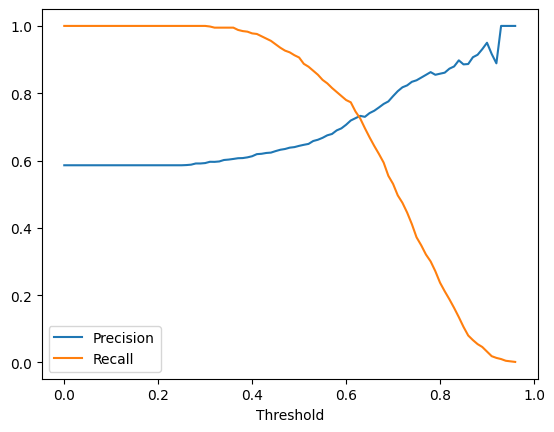

In [54]:
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')

plt.xlabel('Threshold')
plt.legend()
plt.show()

Question 4: F1 score                                                                                        
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both.                                              

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01                                         

At which threshold F1 is maximal?                                                               

0.21                                                                                            
0.41                                                                
0.61                                                                                
0.81                                                                

In [60]:
scores=[]
for t in thresholds:
    y_pred=(y_pred_proba>=t).astype(int)
    f1score=f1_score(y_val, y_pred, zero_division=0)
    scores.append((t, f1score))
df_scores=pd.DataFrame(scores, columns=['thresholds', 'f1_scores'])
df_scores=df_scores[~(df_scores['f1_scores']==0)]
print(df_scores.sort_values('f1_scores', ascending=False).head())


    thresholds  f1_scores
41        0.41   0.757616
42        0.42   0.756325
43        0.43   0.756032
45        0.45   0.754768
44        0.44   0.754717


Question 5: 5-Fold CV                                                                                                   
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:                   

KFold(n_splits=5, shuffle=True, random_state=1)                                                         
Iterate over different folds of df_full_train                                                                           
Split the data into train and validation                                                        
Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
Use AUC to evaluate the model on validation                                                 
How large is standard deviation of the scores across different folds?                                       

0.001                                                                       
0.007                                                                                           
0.013                                                                                           
0.060

In [62]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kf.split(X_full_train):

    df_train = X_full_train.iloc[train_idx]
    df_val = X_full_train.iloc[val_idx]

    y_train = df_train['converted']
    y_val = df_val['converted']

    X_train = df_train.drop(columns=['converted'])
    X_val = df_val.drop(columns=['converted'])

    train_dicts = X_train.to_dict(orient='records')
    val_dicts = X_val.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    X_train_enc = dv.fit_transform(train_dicts)
    X_val_enc = dv.transform(val_dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train_enc, y_train)

    y_pred = model.predict_proba(X_val_enc)[:, 1]

    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)

print("AUC scores:", scores)
print("Mean:", np.mean(scores))
print("Std:", np.std(scores))

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean: 0.7317269710972524
Std: 0.006853233151022138


Question 6: Hyperparameter Tuning                                                                                   
Now let's use 5-Fold cross-validation to find the best parameter C                                                      

Iterate over the following C values: [0.000001, 0.001, 1]                                               
Initialize KFold with the same parameters as previously                                         
Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)                              
Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).                   
Which C leads to the best mean ROC AUC?                                                                             

0.000001                                                                                
0.001                                                                                                           
1                                                                                                           
If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.          

In [63]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
C_values = [0.000001, 0.001, 1]
for C in C_values:
    scores = []
    for train_idx, val_idx in kfold.split(X_full_train):
        df_train = X_full_train.iloc[train_idx]
        df_val = X_full_train.iloc[val_idx]
        y_train = df_train['converted']
        y_val = df_val['converted']
        X_train = df_train.drop(columns=['converted'])
        X_val = df_val.drop(columns=['converted'])
        train_dicts = X_train.to_dict(orient='records')
        val_dicts = X_val.to_dict(orient='records')
        dv = DictVectorizer(sparse=False)
        X_train_enc = dv.fit_transform(train_dicts)
        X_val_enc = dv.transform(val_dicts)
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_enc, y_train)
        y_pred = model.predict_proba(X_val_enc)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print(f"C={C}, "f"mean={np.mean(scores):.3f}, "f"std={np.std(scores):.3f}")

C=1e-06, mean=0.617, std=0.019
C=0.001, mean=0.749, std=0.010
C=1, mean=0.732, std=0.007
